# 1. Title, team members and summary
## Project 4: Machine Learning in Climate Analysis and Prediction

**Status:** setup and Phase 1 checkpoint; later experiments are pending.  
**Team:** number and full names pending (GitHub: Edariel22 and pologram1).  
**Repository:** https://github.com/Edariel22/Project4_Climate_Analysis (private).

This working notebook establishes reproducible data acquisition, checks coverage and missingness, computes 1951-1980 temperature anomalies and begins the required EDA. It does not yet report trained-model results. Replace this paragraph with a one-paragraph summary of measured findings at final submission. The local station remains pending campus confirmation.

The nine top-level sections follow D1 exactly. Work progresses through Phases 1-5 in the assignment; the presentation order places unsupervised analysis before supervised models. See `docs/PROJECT_CHECKLIST.md` in GitHub for the complete requirement map.


# 2. Imports, configuration and data loading

**Run:** use Python 3.12 or 3.13 and Run all. In Colab, the first cell installs pinned dependencies; a fresh CPU runtime is sufficient for this checkpoint. Data are downloaded from the original public sources, cached locally and excluded from Git. The city CSV is large. This notebook contains its helpers so a Drive copy does not need private-repository credentials.

Sources: [Berkeley Earth/Kaggle](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data), [NOAA GML](https://gml.noaa.gov/ccgg/trends/data.html), [Rain in Australia](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package), [Meteostat](https://dev.meteostat.net/python/). Preserve source attribution and verify licenses before redistribution.


In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
IN_COLAB = importlib.util.find_spec('google') is not None and importlib.util.find_spec('google.colab') is not None
PINNED_PACKAGES = ['numpy==2.2.6', 'pandas==2.3.3', 'scikit-learn==1.7.2', 'imbalanced-learn==0.14.0', 'matplotlib==3.10.7', 'seaborn==0.13.2', 'scipy==1.16.3', 'statsmodels==0.14.5', 'meteostat==2.1.5', 'kagglehub==1.0.3', 'nbformat==5.10.4', 'nbclient==0.10.2', 'ipykernel==6.30.1', 'jupyterlab==4.4.10']
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *PINNED_PACKAGES])
print('Python:', sys.version)
ROOT = Path('/content/project4') if IN_COLAB else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
for folder in ['data/raw', 'data/processed', 'figures', 'docs']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Working directory:', ROOT)


Python: 3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]
Working directory: C:\Users\edari\OneDrive - Universidad Ana G. Mendez\UAGM\Concentration_Courses\Machine Learning\Final_Project


In [2]:
"""Reproducible Phase 1 acquisition and diagnostics; embedded in the Colab notebook.

Sources and methodological choices are documented in data/README.md and docs/.
No synthetic observations or model results are substituted for missing downloads.
"""
from pathlib import Path
from datetime import datetime, timezone, date
import hashlib
import json
import shutil
import urllib.request
import numpy as np
import pandas as pd

SEED = 42
GLOBAL_SERIES = "LandAndOceanAverageTemperature"
CITY_PAIRS = [
    ("New York", "United States"), ("London", "United Kingdom"),
    ("Paris", "France"), ("Cairo", "Egypt"), ("Bombay", "India"),
    ("Tokyo", "Japan"), ("Sydney", "Australia"),
    ("Cape Town", "South Africa"), ("S\u00e3o Paulo", "Brazil"),
    ("La Plata", "Argentina"),
]

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def acquire_data(root, station_id=None, start="2000-01-01", end="2025-12-31"):
    """Cache source data locally. A station must be explicitly selected by ID."""
    import kagglehub
    root = Path(root)
    raw = root / "data/raw"
    raw.mkdir(parents=True, exist_ok=True)
    records = []
    paths = {}
    files = [
        ("global", "berkeleyearth/climate-change-earth-surface-temperature-data/versions/2", "GlobalTemperatures.csv"),
        ("cities", "berkeleyearth/climate-change-earth-surface-temperature-data/versions/2", "GlobalLandTemperaturesByCity.csv"),
        ("rain", "jsphyg/weather-dataset-rattle-package/versions/2", "weatherAUS.csv"),
    ]
    for key, handle, filename in files:
        target = raw / filename
        cache_path = None
        if not target.exists():
            cache_path = Path(kagglehub.dataset_download(handle, path=filename))
            shutil.copy2(cache_path, target)
        paths[key] = target
        records.append(dict(dataset=key, source=f"https://www.kaggle.com/datasets/{handle}", version=2,
                            file=filename, sha256=sha256(target), bytes=target.stat().st_size,
                            resolved_cache_path=str(cache_path) if cache_path else None))
    url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
    target = raw / "co2_mm_mlo.csv"
    if not target.exists():
        with urllib.request.urlopen(url, timeout=90) as response:
            content = response.read()
        if b"year,month" not in content.replace(b" ", b""):
            raise ValueError("NOAA response is not the expected monthly CSV")
        target.write_bytes(content)
    paths["co2"] = target
    records.append(dict(dataset="co2", source=url, file=target.name,
                        sha256=sha256(target), bytes=target.stat().st_size))
    if station_id:
        import meteostat as ms
        target = raw / f"meteostat_{station_id}_{start}_{end}.csv"
        if not target.exists():
            daily = ms.daily(ms.Station(id=str(station_id)), date.fromisoformat(start),
                             date.fromisoformat(end)).fetch()
            if daily.empty:
                raise ValueError(f"No daily observations for station {station_id}")
            daily.to_csv(target, index_label="time")
        paths["station"] = target
        records.append(dict(dataset="station", source="https://meteostat.net/", station_id=station_id,
                            requested_start=start, requested_end=end,
                            file=target.name, sha256=sha256(target), bytes=target.stat().st_size))
    manifest_path = raw / "manifest.json"
    # Preserve the original retrieval metadata when reusing an unchanged snapshot.
    previous = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    previous_records = {r["file"]: r for r in previous.get("files", [])}
    now = datetime.now(timezone.utc).isoformat()
    for record in records:
        old = previous_records.get(record["file"], {})
        record["retrieved_utc"] = old.get("retrieved_utc", now) if old.get("sha256") == record["sha256"] else now
        if old.get("sha256") == record["sha256"] and not record.get("resolved_cache_path"):
            record["resolved_cache_path"] = old.get("resolved_cache_path")
    manifest_path.write_text(json.dumps({"files": records}, indent=2), encoding="utf-8")
    return paths

def coverage(df, date_column, location_column=None):
    dates = pd.to_datetime(df[date_column])
    return {"rows": len(df), "columns": len(df.columns),
            "first_date": str(dates.min().date()), "last_date": str(dates.max().date()),
            "locations": int(df[location_column].nunique()) if location_column else 1,
            "missing_cells": int(df.isna().sum().sum())}

def load_core(paths):
    glob = pd.read_csv(paths["global"], parse_dates=["dt"])
    co2 = pd.read_csv(paths["co2"], comment="#", skipinitialspace=True)
    co2.columns = co2.columns.str.strip()
    co2["dt"] = pd.to_datetime(dict(year=co2.year, month=co2.month, day=1))
    # NOAA uses negative sentinel values for absent measurements.
    for column in ["average", "deseasonalized", "ndays", "sdev", "unc"]:
        if column in co2:
            co2[column] = co2[column].mask(co2[column] < 0)
    rain = pd.read_csv(paths["rain"], parse_dates=["Date"])
    rain = rain.sort_values(["Date", "Location"]).reset_index(drop=True)
    station = pd.read_csv(paths["station"], parse_dates=["time"]) if "station" in paths else None
    return glob, co2, rain, station

def scan_cities(path, pairs=CITY_PAIRS):
    """Scan all rows in chunks; retain all dates for the 10 specified city/country pairs.

    Aggregate 1961-1990 climatologies for all cities (no random downsampling).
    Geographic key includes coordinates, avoiding accidental merging of namesakes.
    """
    keys = ["City", "Country", "Latitude", "Longitude"]
    chosen, grouped, missing = [], [], None
    locations = set()
    n = 0
    first, last = None, None
    for chunk in pd.read_csv(path, parse_dates=["dt"], chunksize=250_000):
        n += len(chunk)
        missing = chunk.isna().sum() if missing is None else missing.add(chunk.isna().sum(), fill_value=0)
        cmin, cmax = chunk.dt.min(), chunk.dt.max()
        first = cmin if first is None else min(first, cmin)
        last = cmax if last is None else max(last, cmax)
        locations.update(map(tuple, chunk[keys].drop_duplicates().to_numpy()))
        mask = pd.MultiIndex.from_frame(chunk[["City", "Country"]]).isin(pairs)
        chosen.append(chunk.loc[mask])
        base = chunk.loc[chunk.dt.between("1961-01-01", "1990-12-31")].copy()
        base["month"] = base.dt.dt.month
        grouped.append(base.groupby(keys + ["month"])["AverageTemperature"].agg(["sum", "count"]))
    selected = pd.concat(chosen, ignore_index=True)
    matched = set(map(tuple, selected[["City", "Country"]].drop_duplicates().to_numpy()))
    absent = set(pairs) - matched
    if absent:
        raise ValueError(f"Selected city/country pairs missing from this source: {sorted(absent)}")
    stats = pd.concat(grouped).groupby(level=list(range(5))).sum()
    stats["mean"] = stats["sum"].div(stats["count"].replace(0, np.nan))
    climatology = stats["mean"].unstack("month")
    counts = stats["count"].unstack("month")
    # Require at least 24 of 30 years for every calendar month.
    climatology = climatology.loc[(counts >= 24).all(axis=1)].copy()
    climatology["annual_range"] = climatology.max(axis=1) - climatology.min(axis=1)
    climatology["latitude"] = [float(k[2][:-1]) * (-1 if k[2][-1] == "S" else 1) for k in climatology.index]
    summary = dict(rows=n, columns=len(missing), first_date=str(first.date()),
                   last_date=str(last.date()), locations=len(locations), missing_cells=int(missing.sum()))
    return selected, climatology, summary, (missing / n).rename("missing_fraction")

def annual_anomalies(glob, column=GLOBAL_SERIES):
    monthly = glob.set_index("dt")[column].sort_index().loc["1850":]
    annual = monthly.resample("YS").agg(["mean", "count"])
    annual.loc[annual["count"] < 12, "mean"] = np.nan
    baseline = annual.loc["1951":"1980", "mean"]
    if len(baseline.dropna()) != 30:
        raise ValueError("The 1951-1980 baseline needs 30 complete annual means")
    annual["anomaly"] = annual["mean"] - baseline.mean()
    annual["rolling_10y"] = annual["anomaly"].rolling(10, min_periods=10).mean()
    return annual

def city_coverage(cities):
    rows = []
    for key, df in cities.groupby(["City", "Country", "Latitude", "Longitude"]):
        valid = df.dropna(subset=["AverageTemperature"])
        test = valid.loc[valid.dt.between("2001-01-01", "2013-12-31")]
        rows.append(dict(city=key[0], country=key[1], latitude=key[2], longitude=key[3],
                         rows=len(df), valid_months=len(valid),
                         first_valid=str(valid.dt.min().date()), last_valid=str(valid.dt.max().date()),
                         test_valid_months=len(test), test_expected_months=156))
    return pd.DataFrame(rows)


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from importlib.metadata import version
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110})
STATION_ID = None  # Set only after campus selection and >=20-year coverage validation.
STATION_START, STATION_END = '2000-01-01', '2025-12-31'
print({package: version(package) for package in ['numpy', 'pandas', 'scikit-learn', 'meteostat', 'kagglehub']})
paths = acquire_data(ROOT, STATION_ID, STATION_START, STATION_END)
glob, co2, rain, station = load_core(paths)
cities, climatology, city_summary, city_missingness = scan_cities(paths['cities'])
summary = {'global': coverage(glob, 'dt'), 'co2': coverage(co2, 'dt'),
           'rain': coverage(rain, 'Date', 'Location'), 'cities_full_file': city_summary}
if station is not None:
    summary['station'] = coverage(station, 'time')
coverage_table = pd.DataFrame(summary).T
display(coverage_table)
coverage_table.to_csv(ROOT / 'docs/data_coverage.csv', index_label='dataset')
display(city_coverage(cities))
city_coverage(cities).to_csv(ROOT / 'docs/city_coverage.csv', index=False)
for name, frame in [('global', glob), ('co2', co2), ('rain', rain), ('selected_cities', cities)]:
    print(name, 'shape:', frame.shape)
    display(frame.head())
    display(frame.isna().mean().sort_values(ascending=False).rename('missing_fraction').to_frame())
display(city_missingness.to_frame())
if station is None:
    print('LOCAL STATION PENDING: campus is not confirmed; no station data or heat results are claimed.')
else:
    print('station shape:', station.shape)
    display(station.head())
    display(station.isna().mean().to_frame('missing_fraction'))


{'numpy': '2.2.6', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'meteostat': '2.1.5', 'kagglehub': '1.0.3'}


C:\Users\edari\OneDrive - Universidad Ana G. Mendez\UAGM\Concentration_Courses\Machine Learning\Final_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,rows,columns,first_date,last_date,locations,missing_cells
global,3192,9,1750-01-01,2015-12-01,1,7224
co2,823,9,1958-03-01,2026-09-01,1,585
rain,145460,23,2007-11-01,2017-06-25,49,343248
cities_full_file,8599212,7,1743-11-01,2013-09-01,3510,728260


,city,country,latitude,longitude,rows,valid_months,first_valid,last_valid,test_valid_months,test_expected_months
0,Bombay,India,18.48N,72.68E,2613,2508,1796-01-01,2013-08-01,152,156
1,Cairo,Egypt,29.74N,31.38E,2460,2442,1808-10-01,2013-08-01,152,156
2,Cape Town,South Africa,32.95S,18.19E,1881,1873,1857-01-01,2013-08-01,152,156
3,La Plata,Argentina,34.56S,58.38W,1901,1900,1855-05-01,2013-08-01,152,156
4,London,United Kingdom,52.24N,0.00W,3239,3166,1743-11-01,2013-08-01,152,156
5,New York,United States,40.99N,74.56W,3239,3119,1743-11-01,2013-09-01,153,156
6,Paris,France,49.03N,2.45E,3239,3166,1743-11-01,2013-08-01,152,156
7,Sydney,Australia,34.56S,151.78E,2073,2071,1841-01-01,2013-08-01,152,156
8,São Paulo,Brazil,23.31S,46.31W,2181,2096,1832-01-01,2013-08-01,152,156
9,Tokyo,Japan,36.17N,139.23E,2025,2020,1845-01-01,2013-08-01,152,156


global shape: (3192, 9)


...

selected_cities shape: (24851, 7)


,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1796-01-01,24.317,2.190,Bombay,India,18.48N,72.68E
1,1796-02-01,23.923,1.484,Bombay,India,18.48N,72.68E
2,1796-03-01,24.407,2.309,Bombay,India,18.48N,72.68E
3,1796-04-01,27.171,1.650,Bombay,India,18.48N,72.68E
4,1796-05-01,29.050,1.290,Bombay,India,18.48N,72.68E


,missing_fraction
AverageTemperature,0.019718
AverageTemperatureUncertainty,0.019718
dt,0.000000
City,0.000000
Country,0.000000
Latitude,0.000000
Longitude,0.000000


,missing_fraction
dt,0.000000
AverageTemperature,0.042345
AverageTemperatureUncertainty,0.042345
City,0.000000
Country,0.000000
Latitude,0.000000
Longitude,0.000000


LOCAL STATION PENDING: campus is not confirmed; no station data or heat results are claimed.


# 3. Exploratory data analysis

Phase 1: at least six figures, each followed by an interpretation. This checkpoint uses actual observed data only. Local heat-frequency EDA will be added after the campus station is confirmed. Early temperature estimates and uncertainty columns must be discussed; no gaps are silently interpolated.


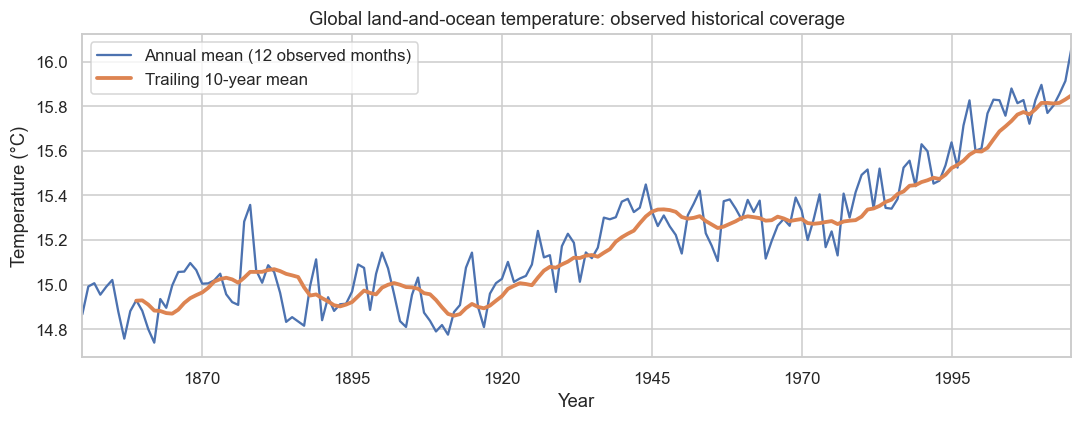

**Interpretation:** Complete annual observations span 1850–2015; the 10-year curve smooths short-term variability. This historical source does not establish coverage up to the current year.

In [4]:
annual = annual_anomalies(glob)
def save_figure(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()

ax = annual['mean'].plot(label='Annual mean (12 observed months)')
annual['mean'].rolling(10, min_periods=10).mean().plot(ax=ax, label='Trailing 10-year mean', linewidth=2.5)
ax.set(title='Global land-and-ocean temperature: observed historical coverage', xlabel='Year', ylabel='Temperature (°C)')
ax.legend()
save_figure('01_global_temperature')
display(Markdown(f"**Interpretation:** Complete annual observations span {annual['mean'].dropna().index.min().year}–{annual['mean'].dropna().index.max().year}; the 10-year curve smooths short-term variability. This historical source does not establish coverage up to the current year."))


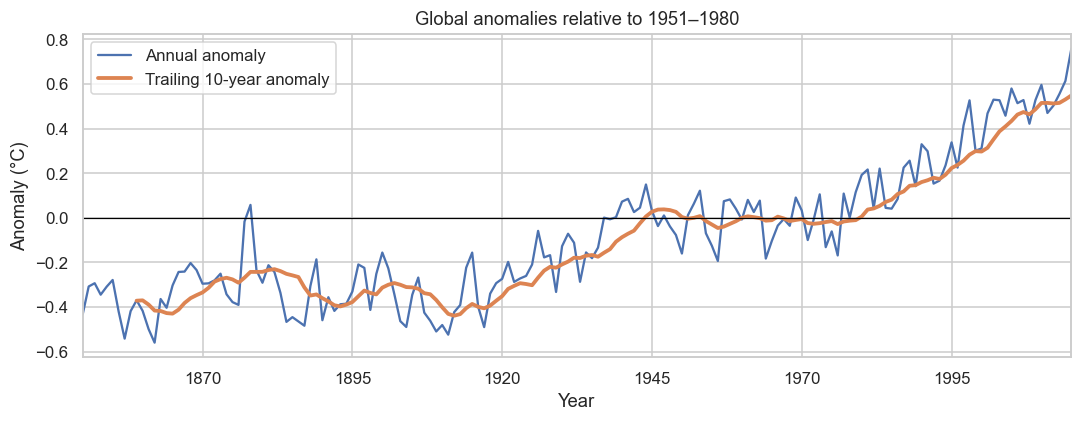

**Interpretation:** Zero represents the mean of the 30 complete annual values in 1951–1980; positive values are warmer than that reference. Quantified warming slopes and confidence intervals belong to Phase 2 and have not been estimated here.

In [5]:
ax = annual['anomaly'].plot(label='Annual anomaly')
annual['rolling_10y'].plot(ax=ax, label='Trailing 10-year anomaly', linewidth=2.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Global anomalies relative to 1951–1980', xlabel='Year', ylabel='Anomaly (°C)')
ax.legend()
save_figure('02_global_anomalies')
display(Markdown('**Interpretation:** Zero represents the mean of the 30 complete annual values in 1951–1980; positive values are warmer than that reference. Quantified warming slopes and confidence intervals belong to Phase 2 and have not been estimated here.'))


C:\Users\edari\AppData\Local\Temp\ipykernel_42872\2194945989.py:3: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\edari\AppData\Local\Temp\ipykernel_42872\2194945989.py:3: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\edari\AppData\Local\Temp\ipykernel_42872\2194945989.py:4: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
C:\Users\edari\AppData\Local\Temp\ipykernel_42872\2194945989.py:4: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
C:\Users\edari\AppData\Local\Temp\ipykernel_42872\2194945989.py:4: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(ROOT / 'figures' / (name + '.png'), dpi=160, bbox_inches='tight')
C:\Users\edari\AppData\

C:\Users\edari\OneDrive - Universidad Ana G. Mendez\UAGM\Concentration_Courses\Machine Learning\Final_Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\edari\OneDrive - Universidad Ana G. Mendez\UAGM\Concentration_Courses\Machine Learning\Final_Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


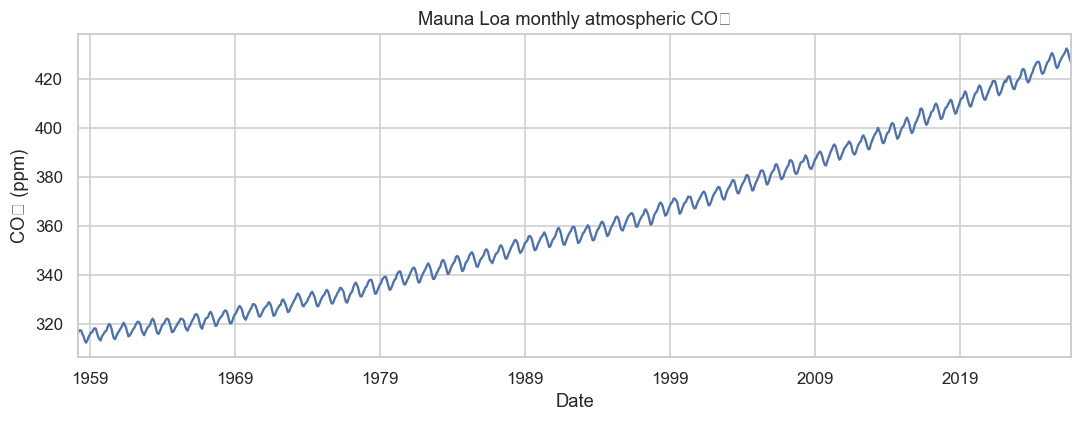

**Interpretation:** There are 823 valid monthly CO₂ measurements in this snapshot. The series combines long-term change with seasonal variability; plotting it alongside temperature does not by itself demonstrate causation.

In [6]:
ax = co2.plot(x='dt', y='average', legend=False)
ax.set(title='Mauna Loa monthly atmospheric CO₂', xlabel='Date', ylabel='CO₂ (ppm)')
save_figure('03_co2')
display(Markdown(f"**Interpretation:** There are {co2['average'].notna().sum():,} valid monthly CO₂ measurements in this snapshot. The series combines long-term change with seasonal variability; plotting it alongside temperature does not by itself demonstrate causation."))


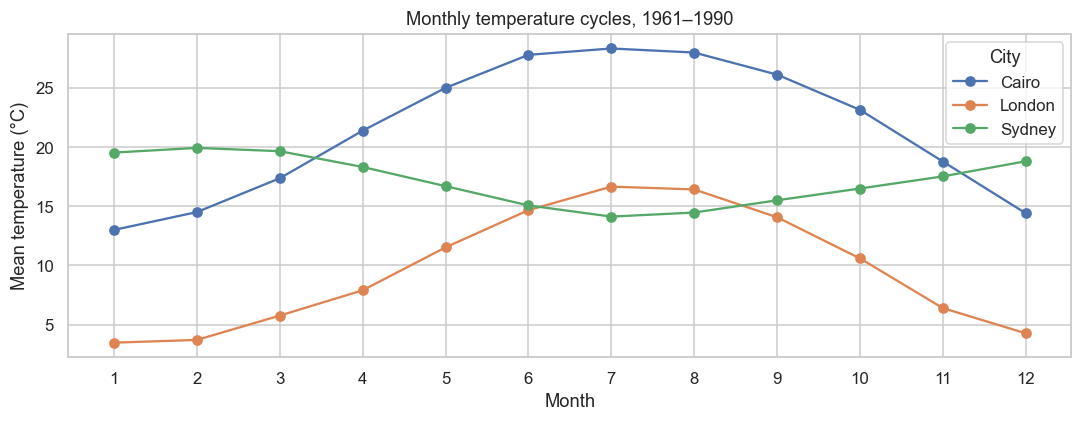

**Interpretation:** Peak climatological temperatures occur in Cairo: month 7, London: month 7, Sydney: month 2. Comparing Northern and Southern Hemisphere cities reveals the seasonal timing difference.

In [7]:
seasonal_cities = cities[cities.City.isin(['London', 'Cairo', 'Sydney'])].copy()
seasonal_cities = seasonal_cities[seasonal_cities.dt.between('1961-01-01', '1990-12-31')]
seasonal_cities['month'] = seasonal_cities.dt.dt.month
cycles = seasonal_cities.groupby(['month', 'City']).AverageTemperature.mean().unstack('City')
ax = cycles.plot(marker='o')
ax.set(title='Monthly temperature cycles, 1961–1990', xlabel='Month', ylabel='Mean temperature (°C)', xticks=range(1, 13))
save_figure('04_monthly_cycles')
peaks = ', '.join(f'{city}: month {int(cycles[city].idxmax())}' for city in cycles)
display(Markdown(f'**Interpretation:** Peak climatological temperatures occur in {peaks}. Comparing Northern and Southern Hemisphere cities reveals the seasonal timing difference.'))


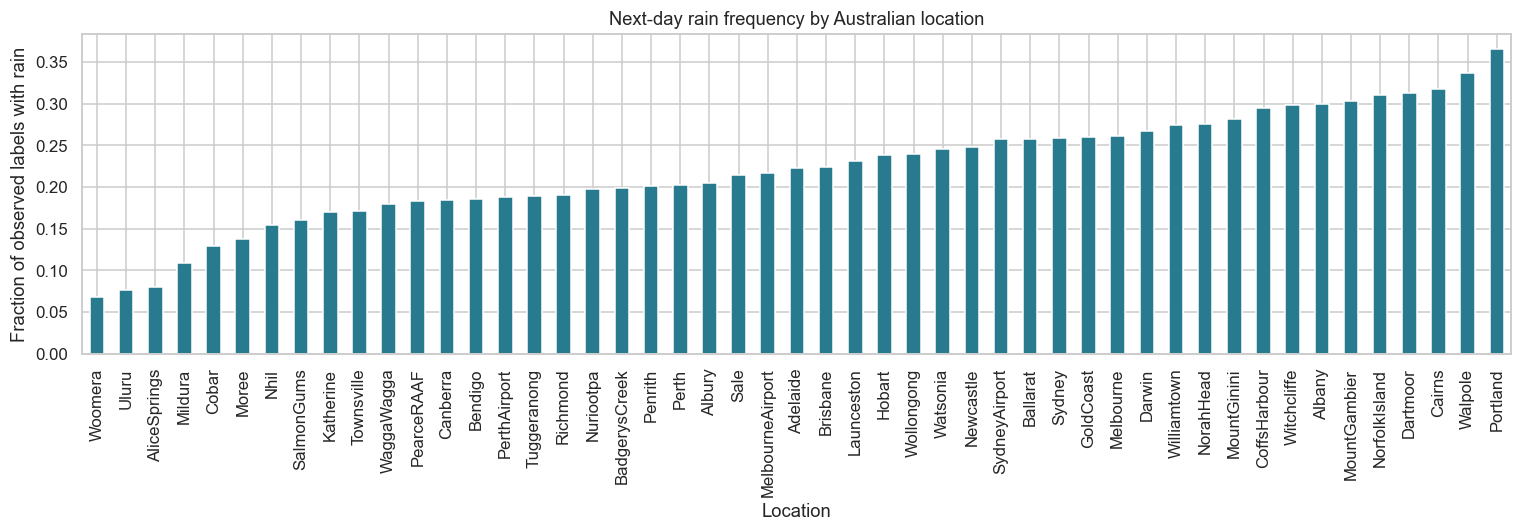

**Interpretation:** Observed rain-label prevalence ranges from 6.8% to 36.5% across locations; missing target labels are excluded from the denominator. This variation motivates reporting per-location test accuracy as well as class-sensitive metrics.

In [8]:
rain_frequency = rain.assign(rain_label=rain.RainTomorrow.map({'Yes': 1.0, 'No': 0.0})).groupby('Location').rain_label.mean().sort_values()
ax = rain_frequency.plot.bar(figsize=(14, 5), color='#287b8e')
ax.set(title='Next-day rain frequency by Australian location', xlabel='Location', ylabel='Fraction of observed labels with rain')
save_figure('05_rain_frequency')
display(Markdown(f'**Interpretation:** Observed rain-label prevalence ranges from {rain_frequency.min():.1%} to {rain_frequency.max():.1%} across locations; missing target labels are excluded from the denominator. This variation motivates reporting per-location test accuracy as well as class-sensitive metrics.'))


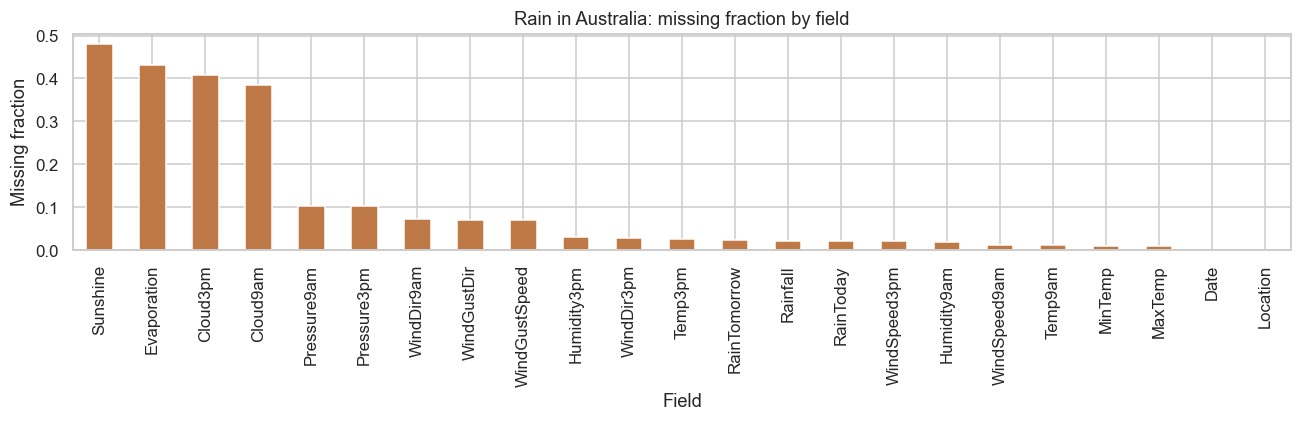

**Interpretation:** Sunshine has the largest missing fraction (48.0%). Predictor imputation must be fitted inside training folds, while rows without the target cannot supply supervised training labels.

In [9]:
missing = rain.isna().mean().sort_values(ascending=False)
ax = missing.plot.bar(color='#be7946', figsize=(12, 4))
ax.set(title='Rain in Australia: missing fraction by field', xlabel='Field', ylabel='Missing fraction')
save_figure('06_missingness')
display(Markdown(f'**Interpretation:** {missing.index[0]} has the largest missing fraction ({missing.iloc[0]:.1%}). Predictor imputation must be fitted inside training folds, while rows without the target cannot supply supervised training labels.'))


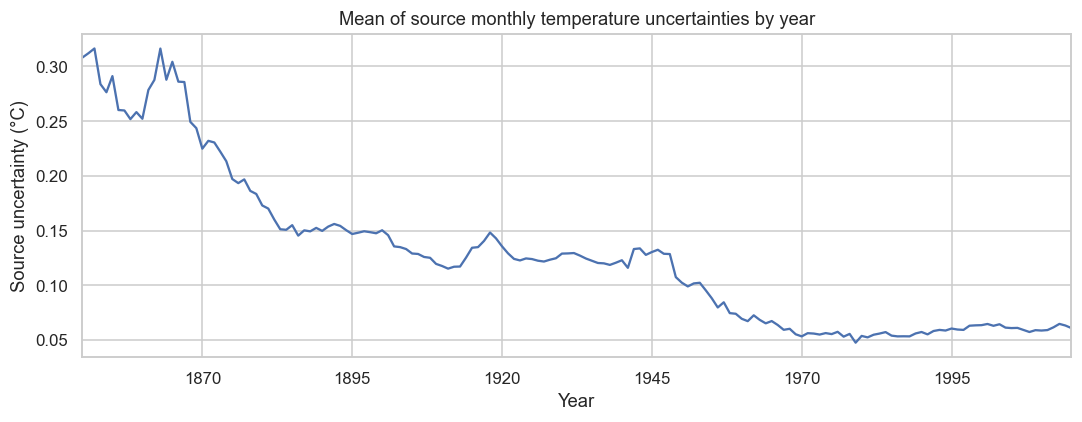

**Interpretation:** This summarizes the uncertainty values supplied with the monthly observations. Averaging those values is descriptive and is not a confidence interval for the annual mean or warming trend.

In [10]:
uncertainty_column = GLOBAL_SERIES + 'Uncertainty'
if uncertainty_column in glob:
    unc = glob.set_index('dt')[uncertainty_column].loc['1850':].resample('YS').mean()
    ax = unc.plot()
    ax.set(title='Mean of source monthly temperature uncertainties by year', xlabel='Year', ylabel='Source uncertainty (°C)')
    save_figure('07_source_uncertainty')
    display(Markdown('**Interpretation:** This summarizes the uncertainty values supplied with the monthly observations. Averaging those values is descriptive and is not a confidence interval for the annual mean or warming trend.'))


# 4. Preprocessing and train / validation / test split

Phase 1 documents the prescribed boundaries; model fitting begins in later phases.

- Global trends: use 1850 onward, compare 1850–1974 and 1975–latest available. Align annual CO₂ from 1958 onward.
- Monthly forecasting: training target dates through 2000, test target dates 2001–2013. TimeSeriesSplit only within training; fit imputers/scalers inside each model Pipeline. A direct 12-month target requires a 12-month purge at validation boundaries so training targets are observed by the issue date.
- Rain: train dates through 2015, test dates from 2016. CV splits must operate on **unique dates**, keeping all locations on the same day together; a one-day purge protects next-day targets.
- Heat: confirm a station with >=20 years; freeze a chronological test interval before modeling. Reindex the daily calendar before creating tomorrow's label. Keep missing tomorrow temperatures as missing targets.
- The assignment's primary heat definition is the full-record 90th percentile; report a training-only-threshold sensitivity analysis separately.
- No missing targets are imputed. Lag/rolling features must only use observations available at issuance. Never forward/back-fill across holdout boundaries.


In [11]:
split_counts = city_coverage(cities)
display(split_counts[['city', 'country', 'test_valid_months', 'test_expected_months']])
rain_labelled = rain.dropna(subset=['RainTomorrow'])
print('Rain train rows through 2015:', int((rain_labelled.Date < '2016-01-01').sum()))
print('Rain test rows from 2016:', int((rain_labelled.Date >= '2016-01-01').sum()))
print('Duplicate rain location/date keys:', int(rain.duplicated(['Location', 'Date']).sum()))
print('Duplicate selected city/month/geography keys:', int(cities.duplicated(['City', 'Country', 'Latitude', 'Longitude', 'dt']).sum()))
print('Do not infer complete 2013 coverage from the requested test end date.')


,city,country,test_valid_months,test_expected_months
0,Bombay,India,152,156
1,Cairo,Egypt,152,156
2,Cape Town,South Africa,152,156
3,La Plata,Argentina,152,156
4,London,United Kingdom,152,156
5,New York,United States,153,156
6,Paris,France,152,156
7,Sydney,Australia,152,156
8,São Paulo,Brazil,152,156
9,Tokyo,Japan,152,156


Rain train rows through 2015: 116219
Rain test rows from 2016: 25974
Duplicate rain location/date keys: 0
Duplicate selected city/month/geography keys: 0
Do not infer complete 2013 coverage from the requested test end date.


# 5. Unsupervised analysis (PCA and k-Means)

**Phase 4 pending.** The source scan has prepared 1961–1990 climatologies for all eligible cities (12 monthly means, annual range, latitude). Eligibility requires >=24 years per calendar month; there is no random subsampling. Fit scaling and PCA, interpret PC1/PC2 loadings, select k using elbow and silhouette, and map coordinates. Source Köppen labels for at least 20 recognizable cities and assess agreement with a contingency table plus ARI/NMI; cluster labels are arbitrary.


In [12]:
print('Cities eligible for clustering:', len(climatology))
display(climatology.head())
print('PCA and k-Means have not yet been fitted.')


Cities eligible for clustering: 3510


,,,month,1,2,3,4,5,6,7,8,9,10,11,12,annual_range,latitude
City,Country,Latitude,Longitude,,,,,,,,,,,,,,
A Coruña,Spain,42.59N,8.73W,8.682600,9.290967,10.391300,11.394967,13.713500,16.587833,18.677600,18.791467,17.812433,14.718367,11.317667,9.255200,10.108867,42.59
Aachen,Germany,50.63N,6.34E,0.891067,1.767600,4.717233,7.950933,12.509933,15.530567,17.267133,17.038533,14.077033,9.925600,4.947600,1.913067,16.376067,50.63
Aalborg,Denmark,57.05N,10.33E,-0.238500,-0.090167,2.262600,5.837800,11.339800,15.229133,16.504700,16.186367,12.961667,9.022900,4.537567,1.273367,16.743200,57.05
Aba,Nigeria,5.63N,8.07E,26.545167,28.127433,28.560400,27.991533,27.361000,26.458233,25.690333,25.657300,25.971133,26.238233,26.706967,26.176300,2.903100,5.63
Abadan,Iran,29.74N,48.00E,13.153633,15.330167,19.593833,24.550267,30.481100,34.177600,35.876167,35.264567,32.373833,27.107467,20.606500,14.894700,22.722533,29.74


PCA and k-Means have not yet been fitted.


# 6. Supervised models

**Phases 2, 3 and 5 pending.** Each subsection below must contain its Pipeline, tuning search, temporal CV mean/SD, best parameters, fit/predict times and final held-out metrics. No model is marked trained by merely listing it. Compare all models on the same eligible rows and horizons.


## Linear regression

**Not trained yet.** Global annual trend and each city forecast; slope per decade with an autocorrelation-aware 95% CI.

## Ridge

**Not trained yet.** City forecasts and annual global models with/without CO₂; tune alpha.

## Lasso

**Not trained yet.** City forecasts and annual global models with/without CO₂; tune alpha and monitor convergence.

## Polynomial regression

**Not trained yet.** Degree 2 and 3 global trends; city forecasts with PolynomialFeatures inside the Pipeline.

## Logistic regression

**Not trained yet.** Rain and local heat classifiers; tune regularization and address imbalance.

## k-Nearest Neighbors

**Not trained yet.** Regressor for every city; classifiers for rain and heat; tune neighbors and weights after fold-fitted scaling.

## Naive Bayes

**Not trained yet.** Rain and heat classifiers; select an appropriate distribution and tune smoothing.

## Support Vector Machine

**Not trained yet.** SVR city forecasts; SVC rain and heat; tune C, kernel and relevant scale parameters.

## Decision tree

**Not trained yet.** Regression and both classification tasks; tune depth and minimum leaf size.

## Random forest

**Not trained yet.** Regression and both classification tasks; tune tree count, depth and leaf size; seed 42.

## Gradient boosting

**Not trained yet.** Regression and both classification tasks; tune learning rate, stages and tree complexity.

## Multilayer perceptron

**Not trained yet.** MLPRegressor and MLPClassifier; tune architecture, regularization and learning rate; record convergence.

## Baselines and local frequency trend

Seasonal naive predicts the same month last year. For a forecast issued at t with target t+12, its prediction is the observed T(t). Use a majority-class baseline for event classification as context. Count local heat days by year, include valid observation counts/rates, and fit a linear trend with uncertainty. These analyses remain pending.


# 7. Model comparison table and plots

**Pending measured experiments.** A master table must identify task, city/station, horizon, model, best hyperparameters, CV mean/SD, held-out metrics, training time and prediction time. Regression needs RMSE/MAE/R² and seasonal-naive skill; classification needs precision/recall/F1/ROC-AUC/confusion matrices and Australian per-location accuracy. Add forecast-vs-actual plots for three cities, ROC curves and a climate-zone world map. Empty cells below are intentional, not zero scores.


In [13]:
comparison = pd.DataFrame(columns=['task', 'location', 'horizon', 'model', 'best_hyperparameters',
    'cv_metric', 'cv_mean', 'cv_std', 'test_rmse', 'test_mae', 'test_r2', 'seasonal_naive_skill',
    'test_precision', 'test_recall', 'test_f1', 'test_roc_auc', 'training_seconds', 'prediction_seconds'])
display(comparison)


,task,location,horizon,model,best_hyperparameters,cv_metric,cv_mean,cv_std,test_rmse,test_mae,test_r2,seasonal_naive_skill,test_precision,test_recall,test_f1,test_roc_auc,training_seconds,prediction_seconds


# 8. Interpretation

Complete after evaluation:
1. Warming per decade, 95% confidence interval and change since 1975.
2. Twelve-month forecast accuracy, skill over seasonal naive, and how errors change with horizon/city.
3. PCA interpretations and cluster agreement with climate zones for 20 cities.
4. Rain/heat predictive ability and local heat-frequency change.

Add feature importance (prefer held-out permutation importance where appropriate), false-negative/false-positive analysis and errors by location/season. Explain why CO₂ association alone does not prove causation, how instruments/station moves/missing records bias trends, and how local heat predictions could inform health or energy planning.


# 9. Conclusions and limitations

This checkpoint establishes data access and exploratory checks. Model performance and scientific conclusions remain unmeasured. Known limitations include historical source endpoints, incomplete months, source uncertainty, the station decision, non-random geographic coverage and the assignment's full-record heat threshold. The report currently contains methodological intentions and must be updated only from measured results.

**Final checks:** all models tuned with temporal CV; no held-out tuning; all nine sections complete; full clean Colab/Kaggle run; source citations; both students' commits; IEEE report 8–12 pages; slides 10–12 pages; instructor access. See GitHub's requirements tracker.

**Implementation references:** [KaggleHub](https://github.com/Kaggle/kagglehub), [Meteostat daily](https://dev.meteostat.net/python/api/meteostat.daily), [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html), and the supplied Project 4 assignment. Record AI assistance according to course policy and distinguish it from each student's contributions.
